In [ ]:
import torch
from torch.utils.data import DataLoader

from deep_models.vae import plot_latent_usage
from deep_models.vae_BrainNetCNN import BrainNetCNNVAE
from deep_models.vae_train import *
from deep_models.data import load_folds, make_splits, S00MILDataset

In [8]:
dev_path = "/dmj/fizmed/mmarzec/licencjat_neuro/DL-NS/split_data/one_site/splits/s00_developmental.npz"
split_k = 5

In [9]:
developamental_folds = load_folds(dev_path)
_, train_idx, val_idx, test_idx = next(split for split in make_splits(developamental_folds) if split[0] == split_k)
print(f"train={len(train_idx)}  val={len(val_idx)}  test={len(test_idx)}")
device = torch.device("cuda")

train=1087  val=132  test=134


In [10]:
train_ds = S00MILDataset(train_idx, max_instances=150, train=True)
val_ds   = S00MILDataset(val_idx,   max_instances=150, train=False)

train_loader = DataLoader(train_ds, batch_size=10, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=10, shuffle=False, num_workers=2, pin_memory=True)

# Build & initialize model

In [11]:
model = BrainNetCNNVAE(latent=64, cond_dim=0).to(device)
init_model(model, train_loader)  # sets Xavier/He weights + band-mean output bias

BrainNetCNNVAE(
  (encoder): Sequential(
    (0): E2EConv(
      (row_conv): Conv2d(5, 32, kernel_size=(1, 17), stride=(1, 1))
      (col_conv): Conv2d(5, 32, kernel_size=(17, 1), stride=(1, 1), bias=False)
    )
    (1): ReLU()
    (2): E2EConv(
      (row_conv): Conv2d(32, 32, kernel_size=(1, 17), stride=(1, 1))
      (col_conv): Conv2d(32, 32, kernel_size=(17, 1), stride=(1, 1), bias=False)
    )
    (3): ReLU()
    (4): DirectedE2N(
      (row_conv): Conv2d(32, 64, kernel_size=(1, 17), stride=(1, 1))
      (col_conv): Conv2d(32, 64, kernel_size=(17, 1), stride=(1, 1), bias=False)
    )
    (5): ReLU()
    (6): Conv2d(64, 256, kernel_size=(17, 1), stride=(1, 1))
    (7): ReLU()
    (8): Flatten(start_dim=1, end_dim=-1)
  )
  (fc_mu): Linear(in_features=256, out_features=64, bias=True)
  (fc_logvar): Linear(in_features=256, out_features=64, bias=True)
  (fc): Linear(in_features=64, out_features=256, bias=True)
  (decoder): Sequential(
    (0): ConvTranspose2d(256, 64, kernel_size=(17

# Train the model & save the best epoch's version

In [12]:
history = fit(
    model,
    train_loader,
    val_loader,
    device,
    epochs=150,
    lr=1e-3,
    beta_max=5e-4,
    anneal_start=50,
    anneal_epochs=50,
    ckpt_path=f"best_vae_bncnn_fold{split_k}.pt")

epoch   1/150  beta 0.00e+00  train 0.6489  val 0.4657  recon 0.4657  MSE 0.00034  KL 165.54  R2 0.393
epoch   2/150  beta 0.00e+00  train 0.3208  val 0.2472  recon 0.2472  MSE 0.00018  KL 406.42  R2 0.678
epoch   3/150  beta 0.00e+00  train 0.2417  val 0.2292  recon 0.2292  MSE 0.00017  KL 447.34  R2 0.702
epoch   4/150  beta 0.00e+00  train 0.2267  val 0.2203  recon 0.2203  MSE 0.00016  KL 439.49  R2 0.713
epoch   5/150  beta 0.00e+00  train 0.2220  val 0.2116  recon 0.2116  MSE 0.00016  KL 410.99  R2 0.724
epoch   6/150  beta 0.00e+00  train 0.2133  val 0.2083  recon 0.2083  MSE 0.00015  KL 433.60  R2 0.729
epoch   7/150  beta 0.00e+00  train 0.2133  val 0.2050  recon 0.2050  MSE 0.00015  KL 414.19  R2 0.733
epoch   8/150  beta 0.00e+00  train 0.2044  val 0.1998  recon 0.1998  MSE 0.00015  KL 456.12  R2 0.740
epoch   9/150  beta 0.00e+00  train 0.2044  val 0.1910  recon 0.1910  MSE 0.00014  KL 449.89  R2 0.751
epoch  10/150  beta 0.00e+00  train 0.1934  val 0.1825  recon 0.1825  MSE

# Evaluate training history

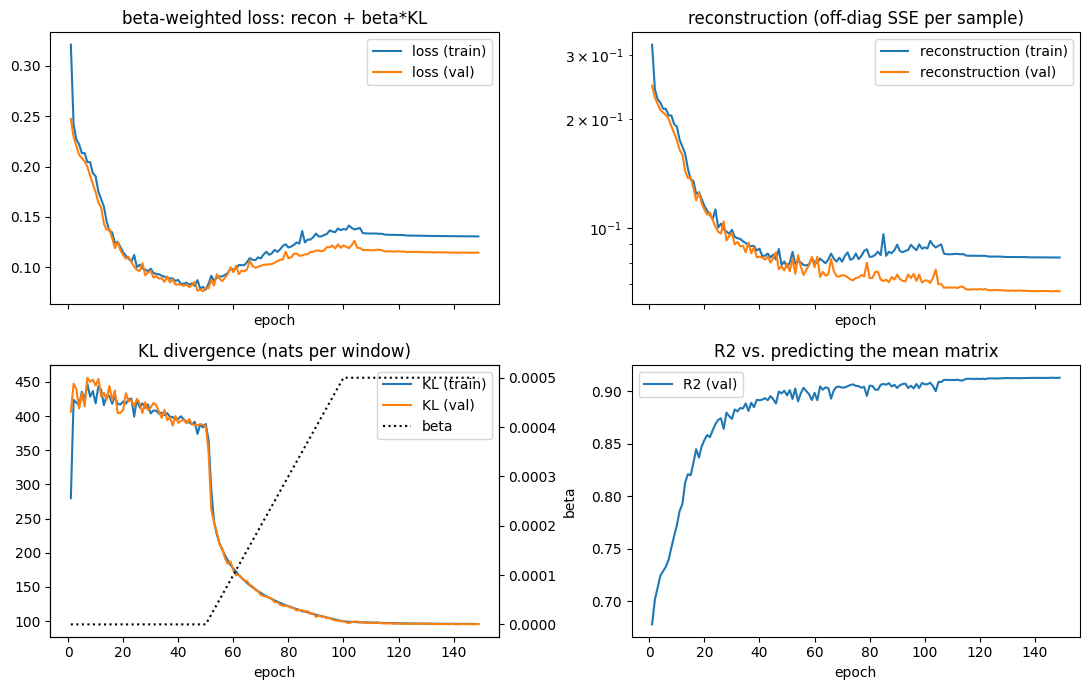

: 

In [ ]:
g = plot_history(history, skip=1)
g.show()